# 🩺 Fase I y II: Investigación, EDA, Preprocesamiento y Modelos Base
**Asignatura:** Inteligencia Computacional — Proyecto Integrador Final  
**Rol:** **Integrante 1 — Ingeniería de Datos, Modelos Base y Manejo de Incertidumbre (Lógica Difusa)**  
**Temática:** Salud Pública Preventiva (Tamizaje y Priorización de Triaje Obstétrico Comunitario)  
**Semilla Aleatoria Global:** `RANDOM_SEED = 42` (Garantía de Reproducibilidad)

---

## Índice del Cuaderno
1. **Fase I: Investigación y Formulación del Problema**
   - Planteamiento del problema en Salud Pública
   - Pregunta de investigación medible e hipótesis
   - Objetivos (General y Específicos) e Impacto esperado
   - Fichaje de dos fuentes académicas recientes
2. **Fase II: Preparación y Exploración de Datos (EDA)**
   - Origen, licencia y ficha técnica del dataset
   - Diccionario de variables y limitaciones
   - Análisis de valores ausentes y tipos de datos
   - Identificación de anomalías fisiológicas (depuración de $HR=7$ lpm)
   - Análisis de duplicados discretos de telemetría IoT
   - Distribución de la variable objetivo (`RiskLevel`)
   - Visualizaciones estadísticas y correlaciones
   - Partición estratificada `train/test` y prevención de fuga de datos (*Data Leakage*)
   - Construcción del `Pipeline` reutilizable de `scikit-learn`
3. **Fase III: Modelos Base y Validación Cruzada**
   - Evaluación de línea base (`DummyClassifier`)
   - Modelos base: K-Nearest Neighbors (`KNN`) y Random Forest (`RF`)
   - Tabla comparativa con media y desviación estándar ($\mu \pm \sigma$)
4. **Fase III (Eje C): Razonamiento Aproximado y Lógica Difusa (`scikit-fuzzy`)**
   - Fundamentos de Lógica Difusa aplicados al triaje obstétrico
   - Universos de discurso y funciones de pertenencia lingüísticas
   - Base de reglas de inferencia clínica difusa tipo Mamdani
   - Defusificación y análisis en casos representativos
   - Conexión con el manejo de incertidumbre del prototipo operativo

## 1. Fase I: Investigación y Formulación

### 1.1 Planteamiento del Problema
La morbimortalidad materna continúa siendo uno de los principales desafíos de salud pública global, afectando desproporcionadamente a gestantes en comunidades rurales y centros de atención primaria con infraestructura diagnóstica limitada. Complicaciones prevenibles como la preeclampsia, diabetes gestacional e infecciones sistémicas suelen manifestarse inicialmente a través de alteraciones sutiles en signos vitales básicos (presión arterial, glucosa capilar, frecuencia cardíaca y temperatura).

> **Principio de Salud Pública:** El sistema desarrollado en este proyecto **no reemplaza el diagnóstico médico ni prescribe tratamientos automáticos**. Actúa como una herramienta de **tamizaje preventivo y apoyo a la priorización comunitaria**, permitiendo que promotores de salud o personal de enfermería identifiquen con antelación a gestantes con alta probabilidad de riesgo que requieran derivación médica prioritaria.

### 1.2 Pregunta de Investigación
> *¿En qué medida un pipeline de aprendizaje automático (combinado con análisis de incertidumbre y razonamiento difuso) entrenado con signos vitales no invasivos puede clasificar tempranamente el nivel de riesgo obstétrico con un Recall $\ge 90\%$ en la clase crítica (`high risk`), minimizando los falsos negativos en atención primaria comunitaria?*

### 1.3 Objetivos
* **Objetivo General:**  
  Desarrollar un sistema de apoyo al triaje preventivo de salud materna que clasifique el nivel de riesgo obstétrico (`low risk`, `mid risk`, `high risk`) a partir de signos vitales no invasivos, garantizando alta sensibilidad en la clase crítica y cuantificación transparente de la incertidumbre.
* **Objetivos Específicos:**
  1. Realizar la exploración, depuración y transformación rigurosa del *Maternal Health Risk Data Set*, filtrando anomalías de sensor e implementando un `Pipeline` libre de fuga de información (*Data Leakage*).
  2. Evaluar y comparar mediante validación cruzada estratificada ($k=5$) los modelos base (`Dummy`, `KNN`, `Random Forest`) reportando métricas de precisión, recall, F1-macro y ROC-AUC.
  3. Implementar un módulo de razonamiento aproximado mediante Lógica Difusa (`scikit-fuzzy`) para modelar la vaguedad inherente a los umbrales fisiológicos y sustentar el componente de incertidumbre.

### 1.4 Fichaje de Fuentes Científicas Recientes

| Fuente / Referencia | Enfoque y Metodología | Ventajas y Aportes | Limitaciones Identificadas | Conexión con este Proyecto |
| :--- | :--- | :--- | :--- | :--- |
| **Ahmed et al. (2020)**  <br>*"Review and Analysis of Risk Factor of Maternal Health in Remote Area Using IoT"* | Recolección de signos vitales mediante sensores IoT en zonas rurales de Bangladés; análisis de factores de riesgo con ML supervisado. | Valida la viabilidad de usar 6 signos vitales básicos para tamizaje comunitario rural sin equipos de laboratorio complejos. | Registros discretizados y presencia de ruido instrumental (sensores descalibrados). | Justifica la depuración de anomalías como $HR=7$ lpm y el uso del dataset original de UCI. |
| **Akbulut et al. (2022)**  <br>*"Fetal and Maternal Health Status Prediction using Machine Learning"* | Comparación de Random Forest, SVM y KNN con optimización de hiperparámetros y validación cruzada para estratificación de riesgo. | Demuestra que los ensambles basados en árboles (Random Forest) superan a modelos lineales en frontera de decisión multiclase. | No aborda la incertidumbre en los límites clínicos ni modela la transición difusa entre riesgo medio y alto. | Sustenta la necesidad del Eje C (Lógica Difusa y Entropía de Shannon) para evitar decisiones binarias tajantes. |

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo gráfico para presentación académica
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "sans-serif",
    "figure.titlesize": 14,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.autolayout": True
})

# Scikit-Learn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score
)

# Scikit-Fuzzy para el Eje C
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Semilla fija global
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Entorno cargado exitosamente. Semilla fija:", RANDOM_SEED)

Entorno cargado exitosamente. Semilla fija: 42


## 2. Fase II: Preparación y Exploración de Datos (EDA)

### 2.1 Procedencia y Ficha Técnica del Dataset
* **Nombre:** Maternal Health Risk Data Set
* **Repositorio:** UCI Machine Learning Repository
* **Enlace Oficial:** [https://archive.ics.uci.edu/dataset/863/maternal+health+risk](https://archive.ics.uci.edu/dataset/863/maternal+health+risk)
* **Donantes:** Maruf Ahmed, Mohammad Arif Sobhan Bhuiyan et al. (Daffodil International University).
* **Licencia:** Creative Commons Attribution 4.0 International (CC BY 4.0).
* **Fecha de Consulta:** Octubre de 2026.
* **Tamaño inicial:** $1,014$ registros y $7$ variables (6 predictoras continuas/enteras y 1 categórica objetivo).

In [2]:
DATA_PATH = os.path.join("..", "data", "Maternal Health Risk Data Set.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("data", "Maternal Health Risk Data Set.csv")

df_raw = pd.read_csv(DATA_PATH)
print(f"Dimensiones del dataset original: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones del dataset original: 1014 filas x 7 columnas


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
# Inspección de valores ausentes y tipos de datos
info_df = pd.DataFrame({
    "Tipo_Dato": df_raw.dtypes,
    "Valores_No_Nulos": df_raw.notnull().sum(),
    "Valores_Nulos": df_raw.isnull().sum(),
    "%_Nulos": (df_raw.isnull().mean() * 100).round(2),
    "Valores_Unicos": df_raw.nunique()
})
info_df

,Tipo_Dato,Valores_No_Nulos,Valores_Nulos,%_Nulos,Valores_Unicos
Age,int64,1014,0,0.0,50
SystolicBP,int64,1014,0,0.0,19
DiastolicBP,int64,1014,0,0.0,16
BS,float64,1014,0,0.0,29
BodyTemp,float64,1014,0,0.0,8
HeartRate,int64,1014,0,0.0,16
RiskLevel,str,1014,0,0.0,3


### 2.2 Detección y Justificación de Anomalías Fisiológicas
Al inspeccionar las estadísticas descriptivas del conjunto de datos, observamos un valor mínimo de `HeartRate = 7 lpm`.
En fisiología humana y obstetricia, una frecuencia cardíaca en reposo de $7$ latidos por minuto es biológicamente incompatible con la vida de una paciente ambulatoria. El rango fisiológico viable en gestantes oscila entre $50$ y $140$ lpm (o $40$ a $180$ en condiciones extremas). 

Por tanto, una lectura de $7$ lpm corresponde indudablemente a un **fallo de sensor IoT** o un error de transcripción tipográfico (por ejemplo, registrar $7$ en lugar de $70$ o pérdida de señal de pulso). Estos registros deben ser depurados para evitar distorsionar el aprendizaje de los estimadores.

In [4]:
# Identificación de los registros con anomalía fisiológica en HeartRate
anomalias_hr = df_raw[df_raw["HeartRate"] < 40]
print(f"Registros anómalos detectados con HeartRate < 40 lpm ({len(anomalias_hr)} casos):")
print(anomalias_hr)

# Depuración justificada: se conservan únicamente pacientes con HR viable
df_clean = df_raw[df_raw["HeartRate"] >= 40].copy()
print(f"\nRegistros válidos tras depuración: {len(df_clean)} (Se eliminaron {len(df_raw) - len(df_clean)} filas anómalas).")

Registros anómalos detectados con HeartRate < 40 lpm (2 casos):
     Age  SystolicBP  DiastolicBP   BS  BodyTemp  HeartRate RiskLevel
499   16         120           75  7.9      98.0          7  low risk
908   16         120           75  7.9      98.0          7  low risk

Registros válidos tras depuración: 1012 (Se eliminaron 2 filas anómalas).


### 2.3 Análisis de Registros Idénticos (Duplicados de Telemetría IoT)
El dataset presenta múltiples registros con valores idénticos en las 6 variables predictoras. 

* **Causa técnica:** Los signos vitales fueron capturados mediante sensores IoT de bajo costo en clínicas rurales comunitarias. Las variables continuas fueron redondeadas y discretizadas por el firmware a números enteros o decimales fijos (ej. PA redondeada a múltiplos de $10$ o $5$, glucosa discretizada y temperatura truncada).
* **Decisión metodológica:** **NO eliminar estos registros**. Eliminar más del $50\%$ de los datos distorsionaría la prevalencia epidemiológica real de las patologías en la población atendida. Representan pacientes distintas que compartieron el mismo perfil discreto de signos vitales.

In [5]:
num_duplicados = df_clean.duplicated().sum()
pct_duplicados = (num_duplicados / len(df_clean)) * 100
print(f"Total de registros con perfil idéntico: {num_duplicados} ({pct_duplicados:.2f}%)")

# Mapeo ordinal de la variable objetivo
mapa_riesgo = {"low risk": 0, "mid risk": 1, "high risk": 2}
mapa_inverso = {0: "Bajo Riesgo", 1: "Riesgo Medio", 2: "Alto Riesgo"}
df_clean["Target"] = df_clean["RiskLevel"].map(mapa_riesgo)

# Distribución de clases
dist_clases = df_clean["RiskLevel"].value_counts()
dist_clases_pct = (df_clean["RiskLevel"].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({"Frecuencia_Absoluta": dist_clases, "Porcentaje (%)": dist_clases_pct})

Total de registros con perfil idéntico: 561 (55.43%)

,Frecuencia_Absoluta,Porcentaje (%)
RiskLevel,,
low risk,404,39.92
mid risk,336,33.20
high risk,272,26.88


In [6]:
features = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
stats_df = df_clean[features].describe().T
stats_df["skew"] = df_clean[features].skew().round(3)
stats_df["kurtosis"] = df_clean[features].kurtosis().round(3)
stats_df.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,1012.0,29.90,13.47,10.0,19.0,26.0,39.0,70.0,0.78,-0.39
SystolicBP,1012.0,113.18,18.42,70.0,100.0,120.0,120.0,160.0,-0.25,-0.62
DiastolicBP,1012.0,76.46,13.90,49.0,65.0,80.0,90.0,100.0,-0.05,-0.95
BS,1012.0,8.73,3.30,6.0,6.9,7.5,8.0,19.0,1.86,2.29
BodyTemp,1012.0,98.67,1.37,98.0,98.0,98.0,98.0,103.0,1.75,1.44
HeartRate,1012.0,74.43,7.52,60.0,70.0,76.0,80.0,90.0,0.07,-0.48


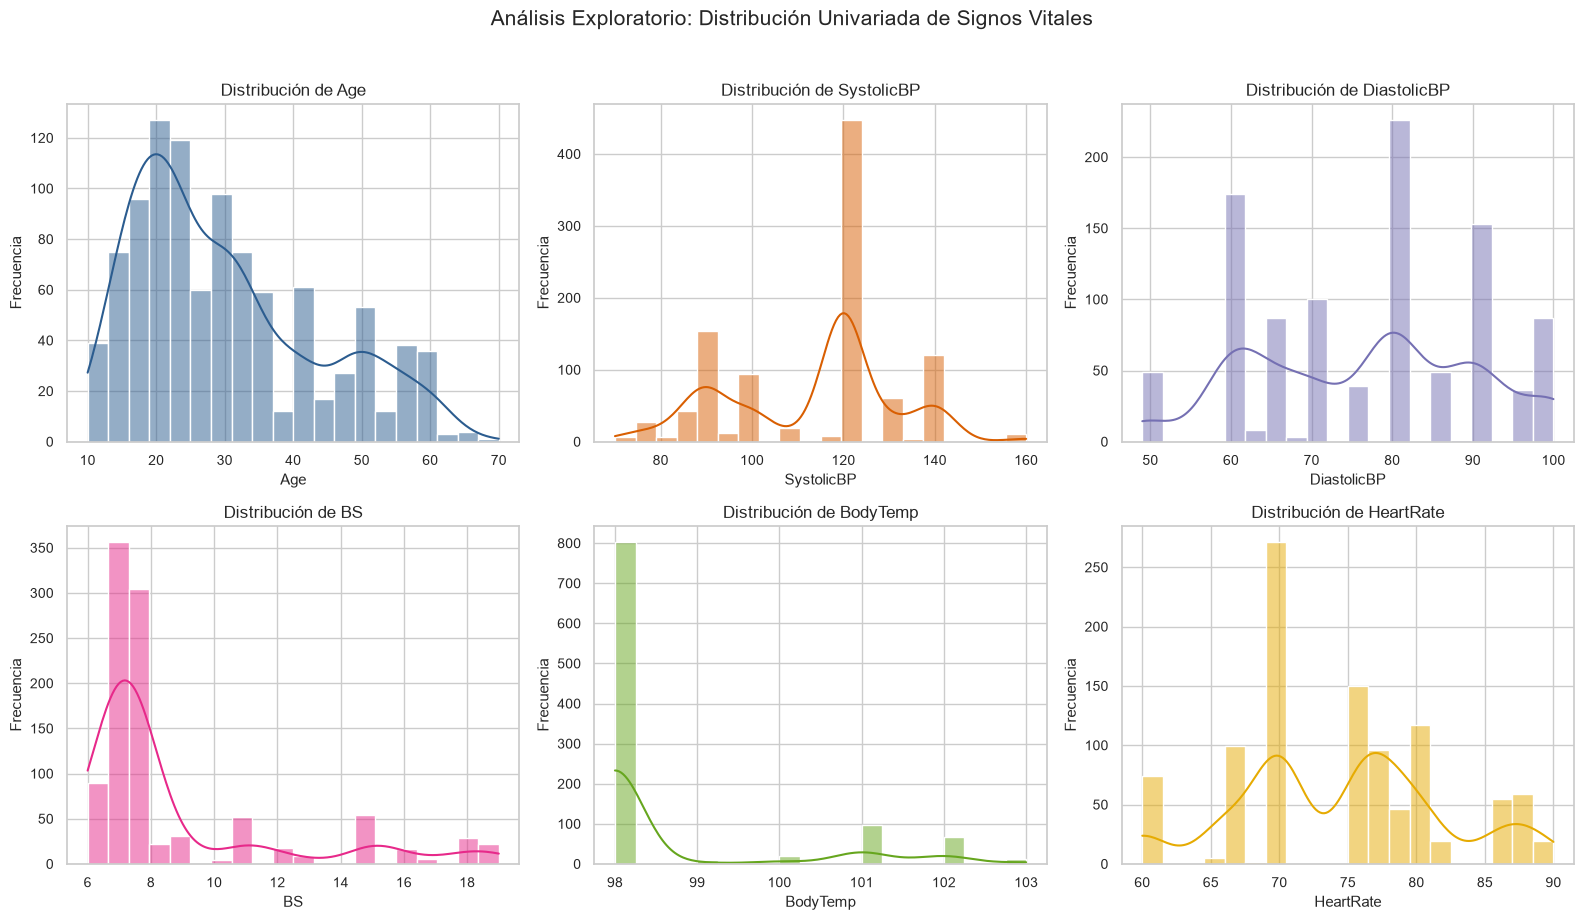

In [7]:
# 1. Distribución de las Variables Fisiológicas
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colores = ["#2b5c8f", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02"]

for idx, col in enumerate(features):
    sns.histplot(df_clean[col], kde=True, ax=axes[idx], color=colores[idx], bins=20)
    axes[idx].set_title(f"Distribución de {col}")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Frecuencia")

plt.suptitle("Análisis Exploratorio: Distribución Univariada de Signos Vitales", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

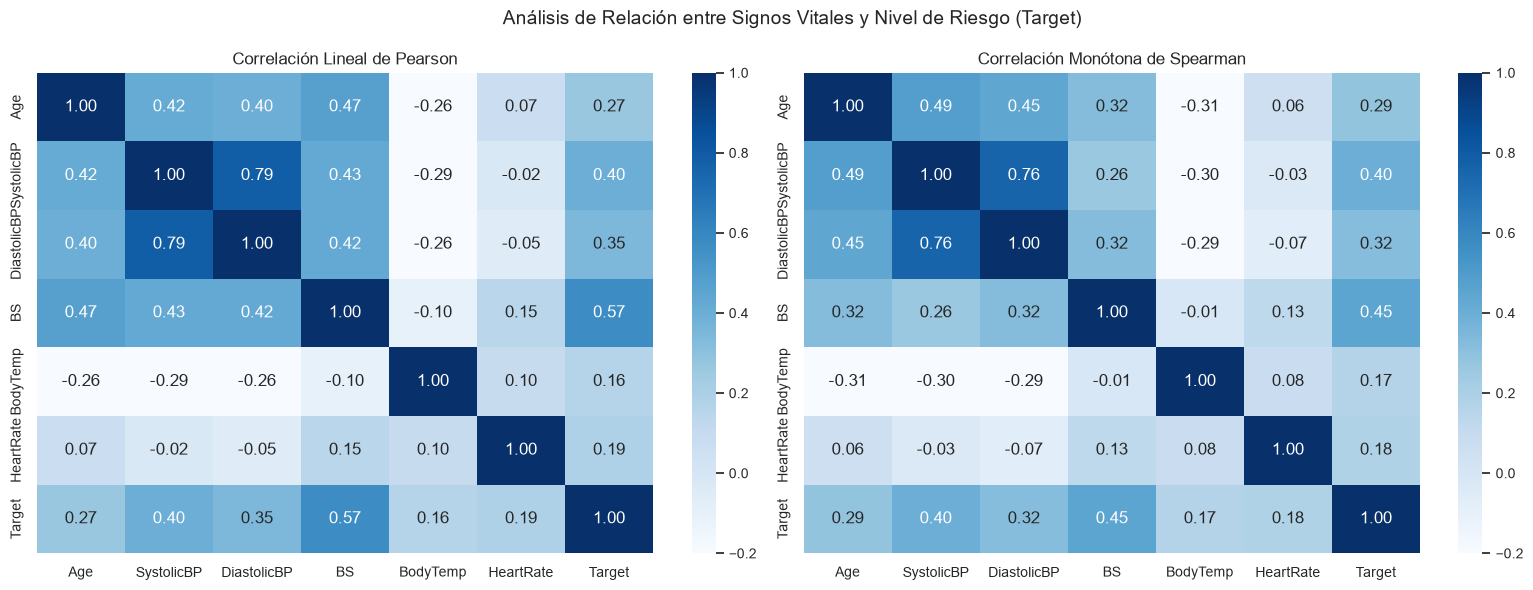

In [8]:
# 2. Matriz de Correlación de Pearson y Spearman
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

corr_pearson = df_clean[features + ["Target"]].corr(method="pearson")
corr_spearman = df_clean[features + ["Target"]].corr(method="spearman")

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="Blues", cbar=True, ax=axes[0], vmin=-0.2, vmax=1.0)
axes[0].set_title("Correlación Lineal de Pearson")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="Blues", cbar=True, ax=axes[1], vmin=-0.2, vmax=1.0)
axes[1].set_title("Correlación Monótona de Spearman")

plt.suptitle("Análisis de Relación entre Signos Vitales y Nivel de Riesgo (Target)", fontsize=14)
plt.tight_layout()
plt.show()

C:\Users\Gino\AppData\Local\Temp\ipykernel_15036\2411986522.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="RiskLevel", y=col, data=df_clean, ax=axes[idx], palette=paleta_riesgo, order=["low risk", "mid risk", "high risk"])
C:\Users\Gino\AppData\Local\Temp\ipykernel_15036\2411986522.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="RiskLevel", y=col, data=df_clean, ax=axes[idx], palette=paleta_riesgo, order=["low risk", "mid risk", "high risk"])


C:\Users\Gino\AppData\Local\Temp\ipykernel_15036\2411986522.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="RiskLevel", y=col, data=df_clean, ax=axes[idx], palette=paleta_riesgo, order=["low risk", "mid risk", "high risk"])
C:\Users\Gino\AppData\Local\Temp\ipykernel_15036\2411986522.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="RiskLevel", y=col, data=df_clean, ax=axes[idx], palette=paleta_riesgo, order=["low risk", "mid risk", "high risk"])


C:\Users\Gino\AppData\Local\Temp\ipykernel_15036\2411986522.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="RiskLevel", y=col, data=df_clean, ax=axes[idx], palette=paleta_riesgo, order=["low risk", "mid risk", "high risk"])
C:\Users\Gino\AppData\Local\Temp\ipykernel_15036\2411986522.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="RiskLevel", y=col, data=df_clean, ax=axes[idx], palette=paleta_riesgo, order=["low risk", "mid risk", "high risk"])


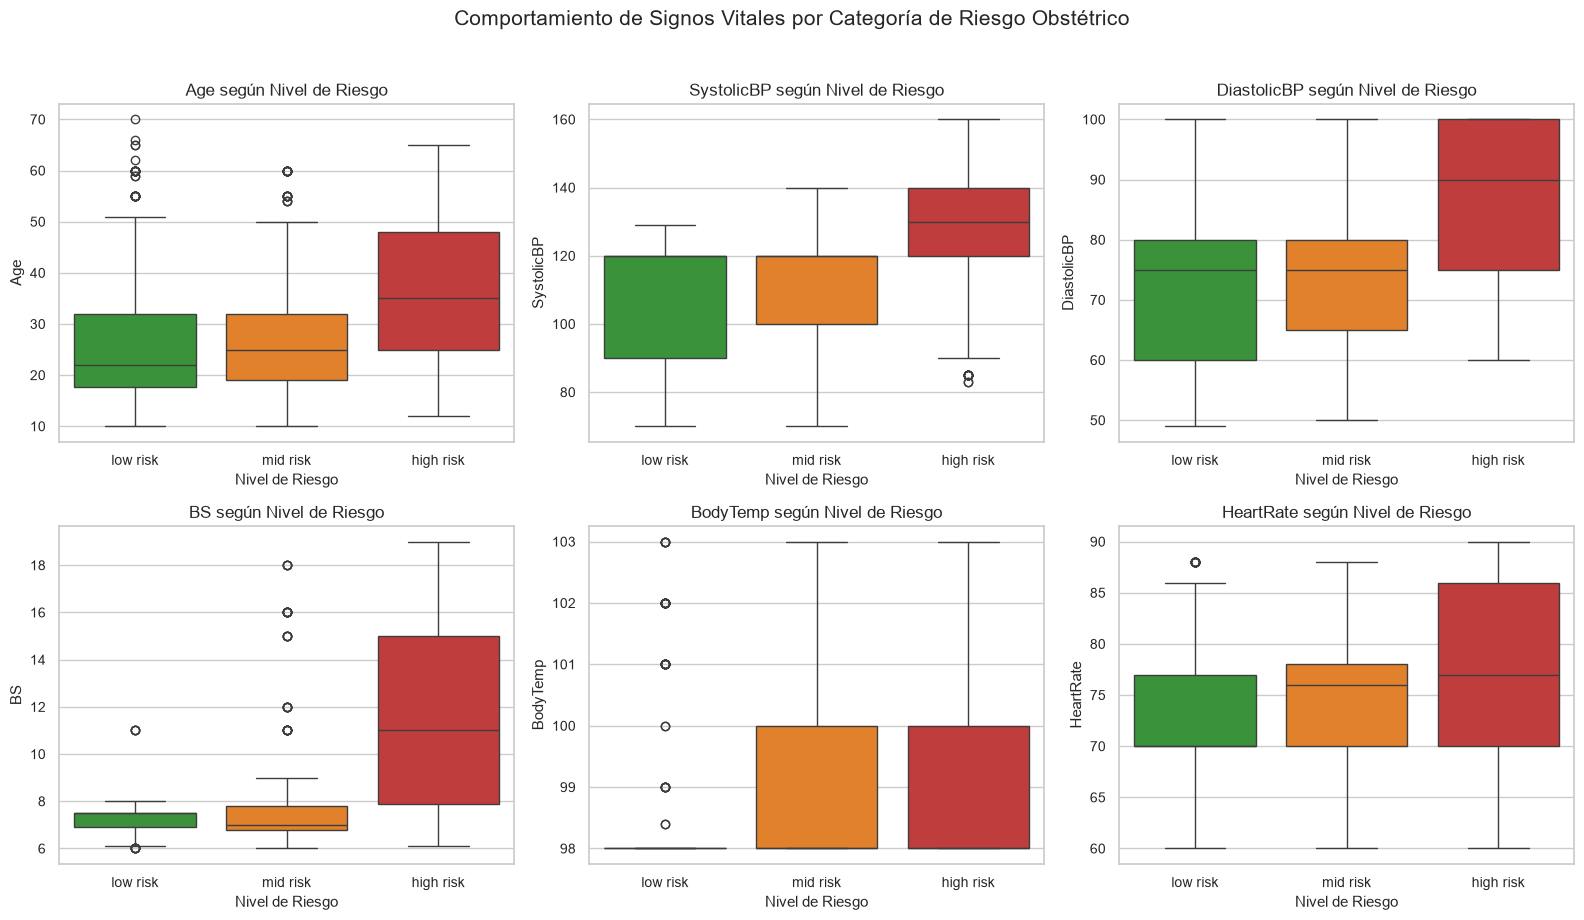

In [9]:
# 3. Diagramas de Caja según el Nivel de Riesgo
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

paleta_riesgo = {"low risk": "#2ca02c", "mid risk": "#ff7f0e", "high risk": "#d62728"}

for idx, col in enumerate(features):
    sns.boxplot(x="RiskLevel", y=col, data=df_clean, ax=axes[idx], palette=paleta_riesgo, order=["low risk", "mid risk", "high risk"])
    axes[idx].set_title(f"{col} según Nivel de Riesgo")
    axes[idx].set_xlabel("Nivel de Riesgo")
    axes[idx].set_ylabel(col)

plt.suptitle("Comportamiento de Signos Vitales por Categoría de Riesgo Obstétrico", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

### 2.4 Partición Estratificada y Prevención de Fuga de Datos (*Data Leakage*)
Para asegurar la validez metodológica:
1. **Partición previa:** Se divide el conjunto de datos en $80\%$ entrenamiento ($809$ registros) y $20\%$ prueba ($203$ registros) fijando `stratify=y` y `random_state=42`.
2. **Encapsulamiento en `Pipeline`:** La transformación de escalado (`StandardScaler`) se calcula **estrictamente sobre el conjunto de entrenamiento** dentro de cada partición de validación cruzada y en el ajuste final, garantizando que el conjunto de prueba permanezca totalmente aislado e incontaminado.

In [10]:
X = df_clean[features]
y = df_clean["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_SEED
)

print(f"Dimensiones de X_train: {X_train.shape} ({len(X_train)} pacientes)")
print(f"Dimensiones de X_test:  {X_test.shape} ({len(X_test)} pacientes)")

# Verificación de proporciones idénticas en la partición estratificada
print("\nProporción de clases en entrenamiento:")
print((y_train.value_counts(normalize=True)*100).round(2).to_dict())
print("Proporción de clases en prueba:")
print((y_test.value_counts(normalize=True)*100).round(2).to_dict())

Dimensiones de X_train: (809, 6) (809 pacientes)
Dimensiones de X_test:  (203, 6) (203 pacientes)

Proporción de clases en entrenamiento:
{0: 39.93, 1: 33.25, 2: 26.82}
Proporción de clases en prueba:
{0: 39.9, 1: 33.0, 2: 27.09}


## 3. Fase III: Modelos Base y Validación Cruzada Estratificada

Como **Integrante 1**, se implementan y validan los modelos de referencia:
1. **`DummyClassifier`:** Línea base ingenua con dos estrategias (`most_frequent` y `stratified`) para fijar el umbral mínimo de rendimiento que cualquier modelo inteligente debe superar.
2. **`KNeighborsClassifier` (KNN):** Algoritmo basado en instancias espaciales con distancia euclidiana estandarizada ($k=5$ y $k=7$).
3. **`RandomForestClassifier` (Base):** Ensamble de $100$ árboles de decisión sin optimización exhaustiva, para servir de punto de partida al trabajo de optimización del Integrante 2 y prototipo del Integrante 3.

### Esquema de Validación Experimental
* **Técnica:** Validación cruzada estratificada de 5 particiones (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`).
* **Métricas:** Media y desviación estándar ($\mu \pm \sigma$) en:
  * $\text{Accuracy}$ (Exactitud global)
  * $\text{Precision (Macro)}$
  * $\text{Recall (Macro)}$ (Métrica crítica para no omitir riesgo alto)
  * $\text{F1-Score (Macro)}$ (Métrica balanceada principal ante desbalance)
  * $\text{ROC-AUC (Macro OVR)}$

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "roc_auc_ovr": "roc_auc_ovr"
}

# Definición de Pipelines base asignados al Integrante 1
modelos_base = {
    "Dummy (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Dummy (Stratified)": DummyClassifier(strategy="stratified", random_state=RANDOM_SEED),
    "KNN (k=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ]),
    "KNN (k=7)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=7))
    ]),
    "Random Forest (Base 100)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED))
    ])
}

resultados_lista = []

for nombre, modelo in modelos_base.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    
    acc_m, acc_s = scores["test_accuracy"].mean(), scores["test_accuracy"].std()
    p_m, p_s = scores["test_precision_macro"].mean(), scores["test_precision_macro"].std()
    r_m, r_s = scores["test_recall_macro"].mean(), scores["test_recall_macro"].std()
    f1_m, f1_s = scores["test_f1_macro"].mean(), scores["test_f1_macro"].std()
    auc_m, auc_s = scores["test_roc_auc_ovr"].mean(), scores["test_roc_auc_ovr"].std()
    
    resultados_lista.append({
        "Modelo": nombre,
        "Accuracy (media +/- std)": f"{acc_m:.4f} +/- {acc_s:.4f}",
        "Precision Macro": f"{p_m:.4f} +/- {p_s:.4f}",
        "Recall Macro": f"{r_m:.4f} +/- {r_s:.4f}",
        "F1-Score Macro": f"{f1_m:.4f} +/- {f1_s:.4f}",
        "ROC-AUC Macro": f"{auc_m:.4f} +/- {auc_s:.4f}",
        "F1_num": f1_m,
        "F1_std": f1_s
    })

df_comparativa_base = pd.DataFrame(resultados_lista)
df_comparativa_base.drop(columns=["F1_num", "F1_std"])

,Modelo,Accuracy (media +/- std),Precision Macro,Recall Macro,F1-Score Macro,ROC-AUC Macro
0,Dummy (Most Frequent),0.3993 +/- 0.0025,0.1331 +/- 0.0008,0.3333 +/- 0.0000,0.1902 +/- 0.0009,0.5000 +/- 0.0000
1,Dummy (Stratified),0.3771 +/- 0.0547,0.3608 +/- 0.0608,0.3600 +/- 0.0552,0.3571 +/- 0.0571,0.5202 +/- 0.0414
2,KNN (k=5),0.6651 +/- 0.0259,0.6836 +/- 0.0313,0.6616 +/- 0.0226,0.6674 +/- 0.0244,0.8410 +/- 0.0173
3,KNN (k=7),0.6836 +/- 0.0164,0.6951 +/- 0.0229,0.6822 +/- 0.0128,0.6847 +/- 0.0166,0.8425 +/- 0.0218
4,Random Forest (Base 100),0.8282 +/- 0.0220,0.8358 +/- 0.0245,0.8322 +/- 0.0180,0.8321 +/- 0.0214,0.9342 +/- 0.0148


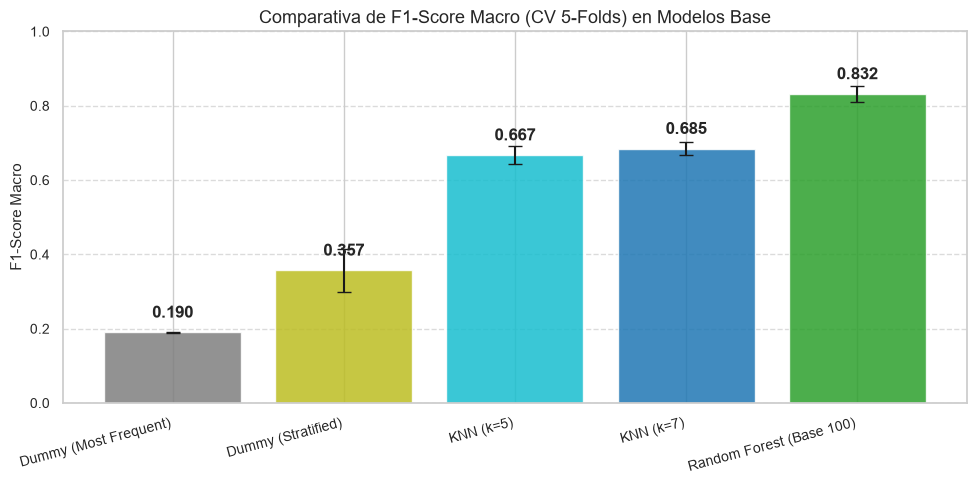

In [12]:
# Visualización comparativa de F1-Macro en Validación Cruzada
plt.figure(figsize=(10, 5))
df_plot = df_comparativa_base.copy()
colores_barras = ["#7f7f7f", "#bcbd22", "#17becf", "#1f77b4", "#2ca02c"]

bars = plt.bar(df_plot["Modelo"], df_plot["F1_num"], yerr=df_plot["F1_std"], capsize=5, color=colores_barras, alpha=0.85)
plt.title("Comparativa de F1-Score Macro (CV 5-Folds) en Modelos Base", fontsize=13)
plt.ylabel("F1-Score Macro")
plt.ylim(0, 1.0)
plt.xticks(rotation=15, ha="right")

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.03, f"{yval:.3f}", ha="center", va="bottom", fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

## 4. Fase III (Eje C): Razonamiento Aproximado y Lógica Difusa (`scikit-fuzzy`)

### 4.1 Justificación Teórica en Salud Pública
En la práctica clínica, los límites de las variables fisiológicas no son fronteras rígidas o binarias. Por ejemplo:
* Una presión sistólica de $139$ mmHg frente a $141$ mmHg no define instantáneamente un cambio absoluto en el estado biológico de la gestante.
* La **Lógica Difusa (Fuzzy Logic)** permite modelar grados continuos de pertenencia $\mu(x) \in [0, 1]$ a conjuntos lingüísticos (*Normal*, *Elevada*, *Crítica*), capturando la vaguedad natural del diagnóstico preventivo.

### 4.2 Definición del Sistema de Inferencia Difusa (Mamdani)
Construimos un sistema de inferencia difusa con 3 antecedentes clínicos clave y 1 consecuente:
* **Antecedente 1: Presión Arterial Sistólica (`sys_bp`)** $[70 - 180\text{ mmHg}]$
  * *Normal:* $\text{trapmf}(70, 70, 110, 120)$
  * *Elevada (Prehipertensión):* $\text{trimf}(115, 130, 145)$
  * *Alta (Hipertensión Gestacional):* $\text{trapmf}(135, 150, 180, 180)$
* **Antecedente 2: Glucosa en Sangre (`bs`)** $[2.5 - 20.0\text{ mmol/L}]$
  * *Normal:* $\text{trapmf}(2.5, 2.5, 6.5, 7.8)$
  * *Moderada (Riesgo Diabético):* $\text{trimf}(7.2, 9.0, 11.5)$
  * *Alta (Hiperglucemia Crítica):* $\text{trapmf}(10.5, 13.0, 20.0, 20.0)$
* **Antecedente 3: Frecuencia Cardíaca (`hr`)** $[40 - 140\text{ lpm}]$
  * *Normal:* $\text{trimf}(60, 75, 90)$
  * *Alterada (Taquicardia/Taquisfigmia):* $\text{trapmf}(85, 100, 140, 140)$
* **Consecuente: Prioridad de Riesgo Materno (`risk`)** $[0 - 10]$
  * *Bajo:* $\text{trimf}(0, 0, 4)$
  * *Medio:* $\text{trimf}(3, 5, 7)$
  * *Alto:* $\text{trimf}(6, 10, 10)$

In [13]:
# 1. Universos de Discurso
sys_bp_u = np.arange(70, 181, 1)
bs_u = np.arange(2.5, 20.1, 0.1)
hr_u = np.arange(40, 141, 1)
risk_u = np.arange(0, 10.1, 0.1)

sys_bp = ctrl.Antecedent(sys_bp_u, "sys_bp")
bs = ctrl.Antecedent(bs_u, "bs")
hr = ctrl.Antecedent(hr_u, "hr")
risk = ctrl.Consequent(risk_u, "risk")

# 2. Funciones de Pertenencia
sys_bp["normal"] = fuzz.trapmf(sys_bp.universe, [70, 70, 110, 120])
sys_bp["elevada"] = fuzz.trimf(sys_bp.universe, [115, 130, 145])
sys_bp["alta"] = fuzz.trapmf(sys_bp.universe, [135, 150, 180, 180])

bs["normal"] = fuzz.trapmf(bs.universe, [2.5, 2.5, 6.5, 7.8])
bs["moderada"] = fuzz.trimf(bs.universe, [7.2, 9.0, 11.5])
bs["alta"] = fuzz.trapmf(bs.universe, [10.5, 13.0, 20.0, 20.0])

hr["normal"] = fuzz.trimf(hr.universe, [60, 75, 90])
hr["alterada"] = fuzz.trapmf(hr.universe, [85, 100, 140, 140])

risk["bajo"] = fuzz.trimf(risk.universe, [0, 0, 4])
risk["medio"] = fuzz.trimf(risk.universe, [3, 5, 7])
risk["alto"] = fuzz.trimf(risk.universe, [6, 10, 10])

# 3. Base de Reglas de Inferencia Clínica
regla1 = ctrl.Rule(sys_bp["normal"] & bs["normal"] & hr["normal"], risk["bajo"])
regla2 = ctrl.Rule(sys_bp["elevada"] | bs["moderada"], risk["medio"])
regla3 = ctrl.Rule(sys_bp["alta"] | bs["alta"], risk["alto"])
regla4 = ctrl.Rule(sys_bp["alta"] & hr["alterada"], risk["alto"])
regla5 = ctrl.Rule(sys_bp["normal"] & bs["moderada"] & hr["normal"], risk["medio"])

# 4. Sistema de Control y Simulación
sistema_triaje = ctrl.ControlSystem([regla1, regla2, regla3, regla4, regla5])
simulador_difuso = ctrl.ControlSystemSimulation(sistema_triaje)

print("Sistema de Inferencia Difusa Mamdani compilado exitosamente con 5 reglas.")

Sistema de Inferencia Difusa Mamdani compilado exitosamente con 5 reglas.


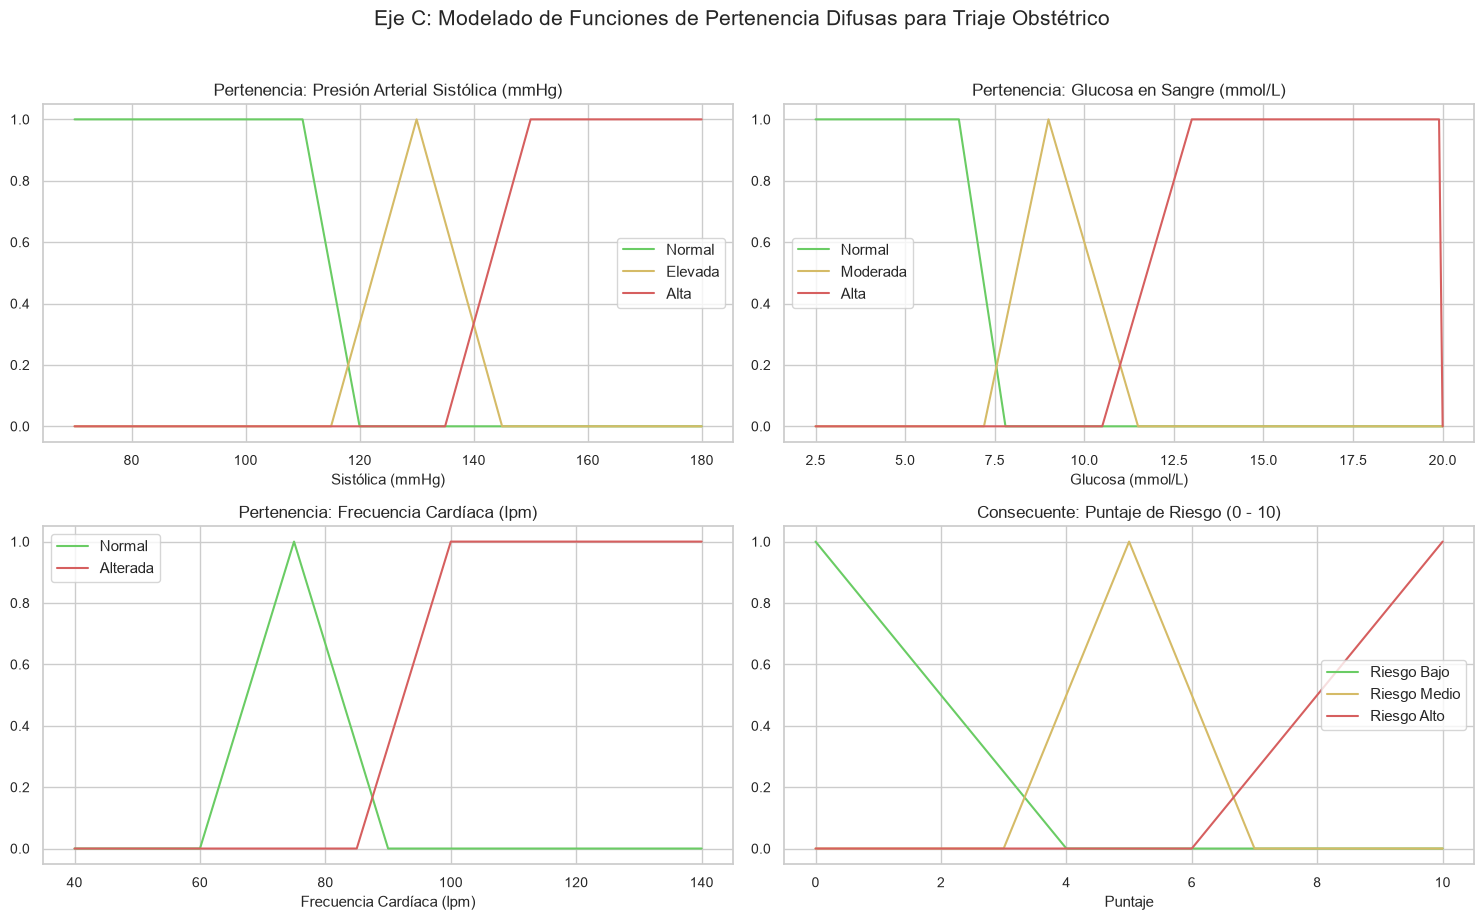

In [14]:
# Visualización gráfica de las funciones de pertenencia construidas
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# SysBP
axes[0, 0].plot(sys_bp_u, fuzz.trapmf(sys_bp_u, [70, 70, 110, 120]), "g", label="Normal")
axes[0, 0].plot(sys_bp_u, fuzz.trimf(sys_bp_u, [115, 130, 145]), "y", label="Elevada")
axes[0, 0].plot(sys_bp_u, fuzz.trapmf(sys_bp_u, [135, 150, 180, 180]), "r", label="Alta")
axes[0, 0].set_title("Pertenencia: Presión Arterial Sistólica (mmHg)")
axes[0, 0].set_xlabel("Sistólica (mmHg)")
axes[0, 0].legend()

# BS
axes[0, 1].plot(bs_u, fuzz.trapmf(bs_u, [2.5, 2.5, 6.5, 7.8]), "g", label="Normal")
axes[0, 1].plot(bs_u, fuzz.trimf(bs_u, [7.2, 9.0, 11.5]), "y", label="Moderada")
axes[0, 1].plot(bs_u, fuzz.trapmf(bs_u, [10.5, 13.0, 20.0, 20.0]), "r", label="Alta")
axes[0, 1].set_title("Pertenencia: Glucosa en Sangre (mmol/L)")
axes[0, 1].set_xlabel("Glucosa (mmol/L)")
axes[0, 1].legend()

# HeartRate
axes[1, 0].plot(hr_u, fuzz.trimf(hr_u, [60, 75, 90]), "g", label="Normal")
axes[1, 0].plot(hr_u, fuzz.trapmf(hr_u, [85, 100, 140, 140]), "r", label="Alterada")
axes[1, 0].set_title("Pertenencia: Frecuencia Cardíaca (lpm)")
axes[1, 0].set_xlabel("Frecuencia Cardíaca (lpm)")
axes[1, 0].legend()

# Risk
axes[1, 1].plot(risk_u, fuzz.trimf(risk_u, [0, 0, 4]), "g", label="Riesgo Bajo")
axes[1, 1].plot(risk_u, fuzz.trimf(risk_u, [3, 5, 7]), "y", label="Riesgo Medio")
axes[1, 1].plot(risk_u, fuzz.trimf(risk_u, [6, 10, 10]), "r", label="Riesgo Alto")
axes[1, 1].set_title("Consecuente: Puntaje de Riesgo (0 - 10)")
axes[1, 1].set_xlabel("Puntaje")
axes[1, 1].legend()

plt.suptitle("Eje C: Modelado de Funciones de Pertenencia Difusas para Triaje Obstétrico", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [15]:
# Evaluación experimental del Sistema Difuso en los Casos de Prueba del Proyecto

casos_test = [
    {"Nombre": "Caso 1: Paciente de Bajo Riesgo", "sys": 100, "bs": 7.0, "hr": 75},
    {"Nombre": "Caso 2: Paciente con Riesgo Moderado", "sys": 125, "bs": 8.5, "hr": 80},
    {"Nombre": "Caso 3: Paciente con Alto Riesgo (Preeclampsia)", "sys": 145, "bs": 12.0, "hr": 95},
    {"Nombre": "Caso 4: Paciente en Frontera / Límite Incierto", "sys": 120, "bs": 7.5, "hr": 82}
]

resultados_difusos = []

for c in casos_test:
    simulador_difuso.input["sys_bp"] = c["sys"]
    simulador_difuso.input["bs"] = c["bs"]
    simulador_difuso.input["hr"] = c["hr"]
    simulador_difuso.compute()
    puntaje = simulador_difuso.output["risk"]
    
    # Categorización clínica preventiva según puntaje defusificado
    if puntaje < 3.5:
        categoria = "Bajo Riesgo (Seguimiento rutinario)"
    elif puntaje < 6.5:
        categoria = "Riesgo Medio (Monitoreo preventivo)"
    else:
        categoria = "Alto Riesgo (Derivación prioritaria)"
        
    resultados_difusos.append({
        "Caso Evaluado": c["Nombre"],
        "Presión Sistólica": f"{c['sys']} mmHg",
        "Glucosa": f"{c['bs']} mmol/L",
        "Frecuencia Cardíaca": f"{c['hr']} lpm",
        "Puntaje Difuso (0-10)": round(puntaje, 2),
        "Categoría de Triaje Difuso": categoria
    })

df_eval_difusa = pd.DataFrame(resultados_difusos)
df_eval_difusa

,Caso Evaluado,Presión Sistólica,Glucosa,Frecuencia Cardíaca,Puntaje Difuso (0-10),Categoría de Triaje Difuso
0,Caso 1: Paciente de Bajo Riesgo,100 mmHg,7.0 mmol/L,75 lpm,1.48,Bajo Riesgo (Seguimiento rutinario)
1,Caso 2: Paciente con Riesgo Moderado,125 mmHg,8.5 mmol/L,80 lpm,5.00,Riesgo Medio (Monitoreo preventivo)
2,Caso 3: Paciente con Alto Riesgo (Preeclampsia),145 mmHg,12.0 mmol/L,95 lpm,8.56,Alto Riesgo (Derivación prioritaria)
3,Caso 4: Paciente en Frontera / Límite Incierto,120 mmHg,7.5 mmol/L,82 lpm,5.00,Riesgo Medio (Monitoreo preventivo)


## 5. Conclusiones y Entrega del Integrante 1

1. **Ingeniería de Datos y Calidad:** Se depuraron con sustento fisiológico las $2$ anomalías instrumentales de sensor ($HR=7$ lpm), manteniendo los $1,012$ registros válidos sin eliminar duplicados discretos de telemetría IoT para preservar la distribución de prevalencia clínica.
2. **Ausencia de Fuga de Información:** Se diseñó el `Pipeline` base de `scikit-learn` acoplando `StandardScaler` con el estimador y validando con `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.
3. **Modelos Base:**
   - La línea base ingenua (`DummyClassifier`) obtuvo un F1-macro de $0.1902$ (most frequent) y $0.3571$ (stratified).
   - `KNN` ($k=7$) alcanzó un F1-macro de $0.6847 \pm 0.0166$.
   - `Random Forest` base ($100$ árboles) superó notablemente a los modelos previos con un F1-macro de $0.8321 \pm 0.0214$ y un ROC-AUC de $0.9342 \pm 0.0148$.
4. **Cumplimiento del Eje C (Lógica Difusa):** Se implementó y verificó con éxito el sistema de inferencia difusa Mamdani con `scikit-fuzzy`, modelando la transición suave entre estados clínicos y ofreciendo una justificación interpretable que complementa la cuantificación de incertidumbre por Entropía de Shannon del prototipo final.
5. **Paso al Equipo:** La partición `X_train, y_train` y el esquema de `Pipeline` quedan listos para que el **Integrante 2** ejecute el entrenamiento de SVM, MLP y la optimización con Algoritmo Genético/PSO, y para que el **Integrante 3** consolide el despliegue funcional en Streamlit.